In [1]:
import os
import shutil
from pathlib import Path
from PIL import ImageFile

# Prevent truncated image crashes
ImageFile.LOAD_TRUNCATED_IMAGES = True

input_dir = Path("/kaggle/input")
unified_dir = Path("/tmp/disaster_data")

# 1. Verify that data is attached to the notebook
if not list(input_dir.iterdir()):
    raise Exception("ERROR: /kaggle/input/ is empty! Click 'Add Data' (top right), search for 'sarthaktandulje/disaster-damage-5class', and add it to your notebook.")

# 2. Dynamically find the dataset folder
base_path = None
for p in input_dir.rglob("disaster_dataset"):
    if p.is_dir() and (p / "disaster_dataset").exists():
        base_path = p.parent
        break

if not base_path:
    raise Exception("ERROR: Could not find the expected 'disaster_dataset' folder. Did you attach the right dataset?")

print(f"Dataset located at: {base_path}")

# 3. Clean slate for the /tmp/ directory
if unified_dir.exists():
    shutil.rmtree(unified_dir)
unified_dir.mkdir(parents=True, exist_ok=True)

# 4. Copy the 5 nested classes
nested_dir = base_path / "disaster_dataset" / "disaster_dataset"
for folder in nested_dir.iterdir():
    if folder.is_dir():
        shutil.copytree(folder, unified_dir / folder.name)

# 5. Copy the Earthquake class
eq_dir = base_path / "earthquake"
if not eq_dir.exists():
    eq_dir = base_path / "disaster_dataset" / "earthquake"
if eq_dir.exists():
    shutil.copytree(eq_dir, unified_dir / "Earthquake")

classes = sorted([d.name for d in unified_dir.iterdir() if d.is_dir()])
print(f"Dataset successfully prepared! Found {len(classes)} classes: {classes}")

Dataset located at: /kaggle/input/datasets/sarthaktandulje/disaster-damage-5class
Dataset successfully prepared! Found 6 classes: ['Earthquake', 'fire', 'flood', 'landslide', 'normal', 'smoke']


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device}")

# Preprocessing & Data Augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load and split dataset (80% Train, 20% Test)
full_dataset = datasets.ImageFolder(root=str(unified_dir), transform=train_transform)

torch.manual_seed(42)
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_set, test_set = random_split(full_dataset, [train_size, test_size])

# Assign validation transform to the test set
test_set.dataset.transform = test_transform

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print(f"Total Images: {len(full_dataset)} | Training: {len(train_set)} | Testing: {len(test_set)}")

# CNN Architecture: Pretrained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

Active Device: cuda
Total Images: 9081 | Training: 7264 | Testing: 1817
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


In [3]:
epochs = 5
history = {
    'train_loss': [], 
    'train_acc': [], 
    'test_loss': [], 
    'test_acc': []
}

for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model.train()
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data).item()
        total_train += labels.size(0)
        
    epoch_train_loss = running_train_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100
    
    # --- TESTING / VALIDATION PHASE ---
    model.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_test_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_test += torch.sum(preds == labels.data).item()
            total_test += labels.size(0)
            
    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = (correct_test / total_test) * 100
    
    # Record history
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['test_loss'].append(epoch_test_loss)
    history['test_acc'].append(epoch_test_acc)
    
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} - Test Acc: {epoch_test_acc:.2f}%")

Epoch [1/5] | Train Loss: 0.2810 - Train Acc: 90.60% | Test Loss: 0.1701 - Test Acc: 94.61%
Epoch [2/5] | Train Loss: 0.0554 - Train Acc: 98.42% | Test Loss: 0.1294 - Test Acc: 95.60%
Epoch [3/5] | Train Loss: 0.0241 - Train Acc: 99.39% | Test Loss: 0.1913 - Test Acc: 94.88%
Epoch [4/5] | Train Loss: 0.0171 - Train Acc: 99.59% | Test Loss: 0.1281 - Test Acc: 96.75%
Epoch [5/5] | Train Loss: 0.0161 - Train Acc: 99.55% | Test Loss: 0.1541 - Test Acc: 95.98%


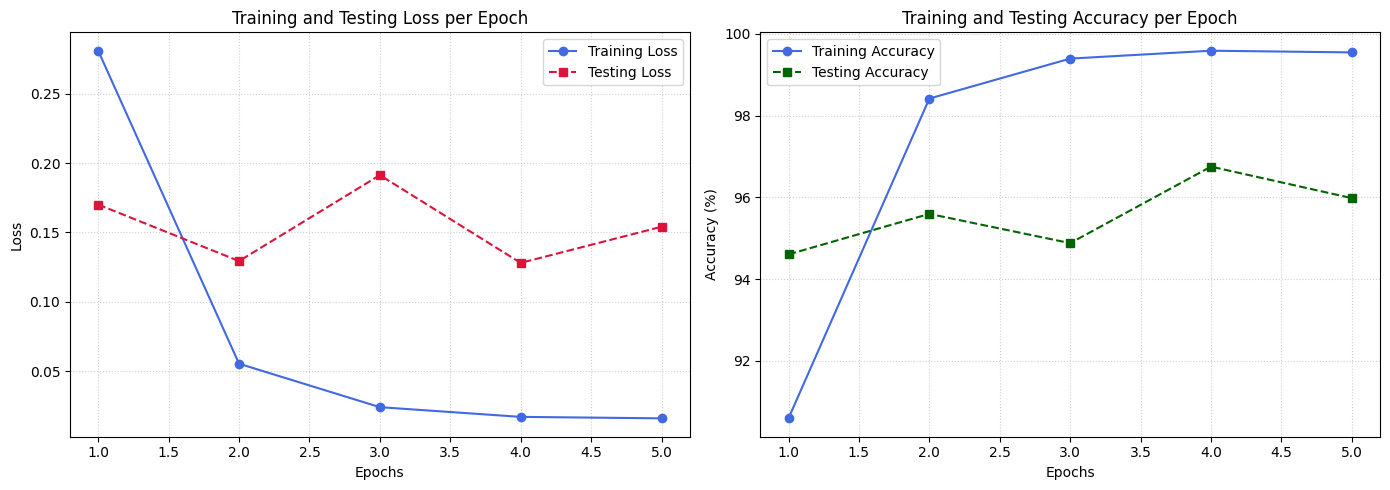

In [4]:
import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(14, 5))

# 1. Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], 'o-', label='Training Loss', color='royalblue')
plt.plot(epochs_range, history['test_loss'], 's--', label='Testing Loss', color='crimson')
plt.title('Training and Testing Loss per Epoch', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# 2. Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], 'o-', label='Training Accuracy', color='royalblue')
plt.plot(epochs_range, history['test_acc'], 's--', label='Testing Accuracy', color='darkgreen')
plt.title('Training and Testing Accuracy per Epoch', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()


==================== TRAINING SET METRICS ====================
Sum of Diagonal Elements (True Positives): 7255
Total Number of Samples: 7264
Calculated Accuracy (Diagonal / Total): 99.88%


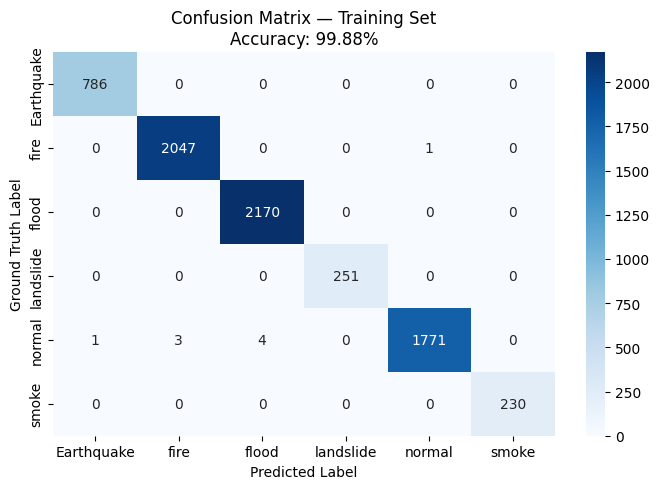


==================== TESTING SET METRICS ====================
Sum of Diagonal Elements (True Positives): 1744
Total Number of Samples: 1817
Calculated Accuracy (Diagonal / Total): 95.98%


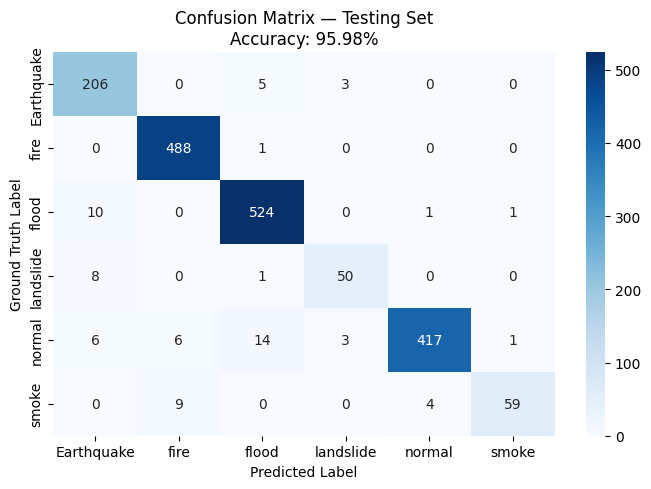

In [5]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

def compute_and_plot_cm(loader, dataset_title):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    cm = confusion_matrix(all_labels, all_preds)
    
    # Advisor's Formula: Sum of Diagonals / Total Sum
    diagonal_sum = np.trace(cm)
    total_samples = np.sum(cm)
    calculated_acc = (diagonal_sum / total_samples) * 100
    
    print(f"\n==================== {dataset_title.upper()} METRICS ====================")
    print(f"Sum of Diagonal Elements (True Positives): {diagonal_sum}")
    print(f"Total Number of Samples: {total_samples}")
    print(f"Calculated Accuracy (Diagonal / Total): {calculated_acc:.2f}%")
    
    # Plotting Heatmap
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.title(f'Confusion Matrix — {dataset_title}\nAccuracy: {calculated_acc:.2f}%', fontsize=12)
    plt.xlabel('Predicted Label')
    plt.ylabel('Ground Truth Label')
    plt.tight_layout()
    plt.show()

# 1. Generate Confusion Matrix for Training Set
compute_and_plot_cm(train_loader, "Training Set")

# 2. Generate Confusion Matrix for Testing Set
compute_and_plot_cm(test_loader, "Testing Set")